# E-Commerce Sales Exploratory Data Analysis (EDA)

**Internship Project:** CodeAlpha Data Analytics Internship  
**Task:** Task 2 — Exploratory Data Analysis (EDA)  
**Domain:** E-Commerce / Retail Analytics  

---

### Notebook Purpose
This notebook provides a structured, beginner-friendly, and rigorous exploratory data analysis of the **UCI Online Retail** transaction dataset.

### Objectives Covered in this Notebook:
1. **Environment Setup & Verification:** Verify dataset file existence before attempting to read.
2. **Data Loading:** Safely load the original Excel dataset without modifying the source file.
3. **Dataset Structure & Dimensions:** Examine initial records (`head`/`tail`), rows, and columns.
4. **Data Types & Schema:** Inspect column data types and memory footprint.
5. **Data Quality Checks:** Identify and calculate missing values and duplicate records.
6. **Descriptive Statistics:** Calculate summary statistics for numerical attributes and unique value counts.
7. **Datetime Parsing & Feature Extraction:** Parse transaction timestamps and extract temporal features (Month, Day of Week, Hour).
8. **Anomalies & Cancellations Investigation:** Inspect negative quantities, negative or zero unit prices, and cancellation codes ('C').
9. **Exploratory Visualizations:** Generate and save insightful visualizations to the `outputs/` folder.
10. **Key Findings & Summary:** Document findings and business insights for the internship task submission.

## 1. Import Required Libraries

We import the standard data analysis and visualization stack:
- **`pandas`**: For data manipulation, tabular data frames, and aggregation.
- **`numpy`**: For numerical operations.
- **`matplotlib.pyplot`**: For core plotting and saving figures.
- **`seaborn`**: For statistical visualizations and styling.
- **`os`**: For directory and file path management.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure consistent plot aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("Required libraries imported successfully.")

Required libraries imported successfully.


## 2. Check File Existence and Load the Dataset

Before attempting to load the data, we check whether the raw Excel file exists in the `data/` directory. This avoids runtime errors and makes the notebook portable whether it is run from the project root or the `notebooks/` directory.

> **Note:** The original Excel dataset is kept read-only and is never modified.

In [2]:
# Detect file path whether notebook is executed from root or notebooks/ directory
if os.path.exists(os.path.join("data", "Online Retail.xlsx")):
    DATA_PATH = os.path.join("data", "Online Retail.xlsx")
    OUTPUTS_DIR = "outputs"
elif os.path.exists(os.path.join("..", "data", "Online Retail.xlsx")):
    DATA_PATH = os.path.join("..", "data", "Online Retail.xlsx")
    OUTPUTS_DIR = os.path.join("..", "outputs")
else:
    raise FileNotFoundError(
        "Dataset 'Online Retail.xlsx' was not found in 'data/' or '../data/'. "
        "Please ensure the Excel file is placed in the data directory before running."
    )

# Ensure the outputs directory exists
os.makedirs(OUTPUTS_DIR, exist_ok=True)

print(f"[OK] Found dataset at: {DATA_PATH}")
print(f"[OK] Outputs will be saved to: {OUTPUTS_DIR}")

# Load the Excel dataset using Pandas
print("Loading Excel file into Pandas DataFrame... (this may take 20-40 seconds)")
df = pd.read_excel(DATA_PATH)
print("Dataset successfully loaded!")

[OK] Found dataset at: ..\data\Online Retail.xlsx
[OK] Outputs will be saved to: ..\outputs
Loading Excel file into Pandas DataFrame... (this may take 20-40 seconds)


Dataset successfully loaded!


## 3. Initial Data Inspection

Let us inspect the first 5 rows and the last 5 rows to verify the loaded data structure and observe typical transaction records.

In [3]:
# Display the first five rows
print("First 5 Rows of the Dataset:")
display(df.head())

# Display the last five rows
print("\nLast 5 Rows of the Dataset:")
display(df.tail())

First 5 Rows of the Dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Last 5 Rows of the Dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


## 4. Dataset Dimensions

We inspect the total number of rows (transactions) and columns (attributes) in the dataset using `df.shape`.

In [4]:
rows, columns = df.shape
print(f"Total Number of Rows (Records):    {rows:,}")
print(f"Total Number of Columns (Features): {columns}")

Total Number of Rows (Records):    541,909
Total Number of Columns (Features): 8


## 5. Column Names and Data Types

Checking column names and data types (`dtypes`) helps us confirm whether each field was parsed into the correct format (e.g. numeric, text, or datetime).

In [5]:
# Summary of columns and data types
dtype_summary = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notnull().sum().values
})
display(dtype_summary)

print("\nDataFrame Info Summary:")
df.info()

,Column Name,Data Type,Non-Null Count
InvoiceNo,InvoiceNo,object,541909
StockCode,StockCode,object,541909
Description,Description,object,540455
Quantity,Quantity,int64,541909
InvoiceDate,InvoiceDate,datetime64[us],541909
UnitPrice,UnitPrice,float64,541909
CustomerID,CustomerID,float64,406829
Country,Country,str,541909



DataFrame Info Summary:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 6. Missing Values Analysis

Missing values (`NaN`) must be identified and quantified. We compute both the absolute count and the percentage of missing values per column.

> **Key Analytical Observation:**
> - Missing values in `CustomerID` occur when transactions are completed by guest or unregistered shoppers.
> - Missing values in `Description` may represent manual administrative entries or uncatalogued items.
> - In exploratory analysis, we **do not** drop missing `CustomerID` rows indiscriminately because those transactions still represent genuine sales and inventory movement.

In [6]:
# Calculate missing counts and percentages
missing_counts = df.isnull().sum()
missing_percentages = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage (%)": missing_percentages.round(2)
})

# Display sorted by missing values count
display(missing_table.sort_values(by="Missing Count", ascending=False))

,Missing Count,Missing Percentage (%)
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


## 7. Duplicate Records Inspection

We check for exact duplicate rows in the dataset to evaluate data entry repetition.

In [7]:
duplicate_rows = df.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_rows:,} ({(duplicate_rows / len(df) * 100):.2f}% of dataset)")

# Display a sample of duplicate records for inspection
if duplicate_rows > 0:
    print("\nSample of Duplicate Records:")
    display(df[df.duplicated(keep=False)].sort_values(by=["InvoiceNo", "StockCode"]).head(10))

Total Duplicate Rows: 5,268 (0.97% of dataset)

Sample of Duplicate Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


## 8. Descriptive Statistics

Descriptive statistics summarize the central tendency, dispersion, and range of numerical features (`Quantity` and `UnitPrice`), as well as unique counts across all attributes.

Notice the minimum values: negative quantities or negative/zero unit prices highlight non-standard transactions that require careful investigation.

In [8]:
# Summary statistics for numerical columns
print("Numerical Attributes Summary Statistics:")
display(df.describe().T)

# Unique values count across all columns
print("\nUnique Value Counts Per Column:")
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique Count": [df[col].nunique() for col in df.columns]
})
display(unique_summary)

Numerical Attributes Summary Statistics:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303



Unique Value Counts Per Column:


,Column,Unique Count
0,InvoiceNo,25900
1,StockCode,4070
2,Description,4223
3,Quantity,722
4,InvoiceDate,23260
5,UnitPrice,1630
6,CustomerID,4372
7,Country,38


## 9. Parse `InvoiceDate` as Datetime & Extract Temporal Attributes

We verify that `InvoiceDate` is in proper datetime format, determine the total timeline covered by the dataset, and extract temporal components (`Year`, `Month`, `YearMonth`, `DayOfWeek`, `Hour`) to enable trend analysis.

In [9]:
# Ensure InvoiceDate is in datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Start Date of Records: {df['InvoiceDate'].min()}")
print(f"End Date of Records:   {df['InvoiceDate'].max()}")
print(f"Overall Date Span:     {df['InvoiceDate'].max() - df['InvoiceDate'].min()}")

# Extract temporal analytical features
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

print("\nSample records with extracted temporal features:")
display(df[['InvoiceNo', 'InvoiceDate', 'YearMonth', 'DayOfWeek', 'Hour']].head())

Start Date of Records: 2010-12-01 08:26:00
End Date of Records:   2011-12-09 12:50:00
Overall Date Span:     373 days 04:24:00



Sample records with extracted temporal features:

,InvoiceNo,InvoiceDate,YearMonth,DayOfWeek,Hour
0,536365,2010-12-01 08:26:00,2010-12,Wednesday,8
1,536365,2010-12-01 08:26:00,2010-12,Wednesday,8
2,536365,2010-12-01 08:26:00,2010-12,Wednesday,8
3,536365,2010-12-01 08:26:00,2010-12,Wednesday,8
4,536365,2010-12-01 08:26:00,2010-12,Wednesday,8


## 10. In-Depth Inspection of Negative Quantities, Prices & Cancellations

In retail transaction datasets, anomalies and non-standard entries provide critical business context:
1. **Cancellations:** Invoices with an `'C'` prefix indicate cancelled orders or customer returns.
2. **Negative Quantities:** May denote returns, damaged goods, or inventory stock corrections.
3. **Zero / Negative Unit Prices:** Frequently indicate manual adjustments, fee adjustments, or promotional items.

> **EDA Principle:** We **do not blindly remove** these records! Removing them would distort the true net sales, return rates, and business reality. Instead, we identify and categorize them.

In [10]:
# Flag invoices starting with 'C' as cancellations
df['IsCancelled'] = df['InvoiceNo'].astype(str).str.startswith('C', na=False)

cancelled_count = df['IsCancelled'].sum()
negative_qty_count = (df['Quantity'] < 0).sum()
zero_price_count = (df['UnitPrice'] == 0).sum()
negative_price_count = (df['UnitPrice'] < 0).sum()

print("=== Anomaly and Cancellation Summary ===")
print(f"Invoices with 'C' (Cancelled Orders): {cancelled_count:,}")
print(f"Transactions with Quantity < 0:      {negative_qty_count:,}")
print(f"Transactions with UnitPrice == 0:     {zero_price_count:,}")
print(f"Transactions with UnitPrice < 0:      {negative_price_count:,}")

# Verify relationship between cancellations and negative quantities
cancelled_have_neg_qty = (df[df['IsCancelled']]['Quantity'] < 0).all()
print(f"\nDo all cancelled invoices ('C') have negative quantity? {cancelled_have_neg_qty}")

# Inspect negative quantities that do NOT have 'C' prefix
unmarked_negatives = df[(df['Quantity'] < 0) & (~df['IsCancelled'])]
print(f"Negative quantities without 'C' prefix: {len(unmarked_negatives):,}")
if len(unmarked_negatives) > 0:
    print("\nSample of negative quantities without 'C' prefix (e.g., inventory write-offs / damages):")
    display(unmarked_negatives[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice']].head())

# Inspect zero or negative unit prices
non_positive_prices = df[df['UnitPrice'] <= 0]
if len(non_positive_prices) > 0:
    print("\nSample of records with UnitPrice <= 0:")
    display(non_positive_prices[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice']].head())

=== Anomaly and Cancellation Summary ===
Invoices with 'C' (Cancelled Orders): 9,288
Transactions with Quantity < 0:      10,624
Transactions with UnitPrice == 0:     2,515
Transactions with UnitPrice < 0:      2

Do all cancelled invoices ('C') have negative quantity? True
Negative quantities without 'C' prefix: 1,336

Sample of negative quantities without 'C' prefix (e.g., inventory write-offs / damages):


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
2406,536589,21777,NaN,-10,0.0
4347,536764,84952C,NaN,-38,0.0
7188,536996,22712,NaN,-20,0.0
7189,536997,22028,NaN,-20,0.0
7190,536998,85067,NaN,-6,0.0



Sample of records with UnitPrice <= 0:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
622,536414,22139,NaN,56,0.0
1970,536545,21134,NaN,1,0.0
1971,536546,22145,NaN,1,0.0
1972,536547,37509,NaN,1,0.0
1987,536549,85226A,NaN,1,0.0


## 11. Transaction Line Total and Revenue Overview

We compute the transaction value (`LineTotal = Quantity * UnitPrice`) to assess gross sales versus returns.

In [11]:
# Compute total value per transaction record
df['LineTotal'] = df['Quantity'] * df['UnitPrice']

gross_revenue = df[df['LineTotal'] > 0]['LineTotal'].sum()
refunds_total = df[df['LineTotal'] < 0]['LineTotal'].sum()
net_revenue = df['LineTotal'].sum()

print("=== Revenue Metric Summary ===")
print(f"Gross Sales (Positive Transactions): £{gross_revenue:,.2f}")
print(f"Returns & Adjustments:              -£{abs(refunds_total):,.2f}")
print(f"Net Sales:                          £{net_revenue:,.2f}")


=== Revenue Metric Summary ===
Gross Sales (Positive Transactions): £10,666,684.54
Returns & Adjustments:              -£918,936.61
Net Sales:                          £9,747,747.93


## 12. Exploratory Visualizations

We generate visualizations to analyze sales volume trends, geographic concentration, hourly purchasing patterns, and top products.

All generated visual figures are saved to the `outputs/` directory for task documentation.

### 12.1 Monthly Transaction Volume Trend

Saved chart to: ..\outputs\monthly_transaction_volume.png


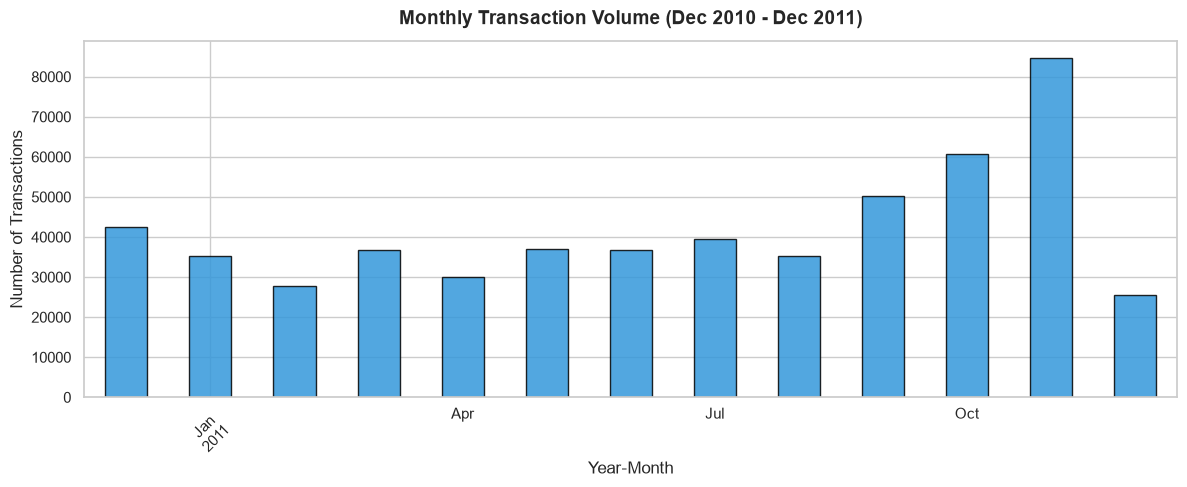

In [12]:
monthly_counts = df.groupby('YearMonth').size()

plt.figure(figsize=(12, 5))
monthly_counts.plot(kind='bar', color='#3498db', edgecolor='black', alpha=0.85)
plt.title("Monthly Transaction Volume (Dec 2010 - Dec 2011)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Year-Month", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

# Save output plot
plot_1_path = os.path.join(OUTPUTS_DIR, "monthly_transaction_volume.png")
plt.savefig(plot_1_path, dpi=300)
print(f"Saved chart to: {plot_1_path}")
plt.show()

### 12.2 Top 10 Countries by Transaction Count

Saved chart to: ..\outputs\top_10_countries.png


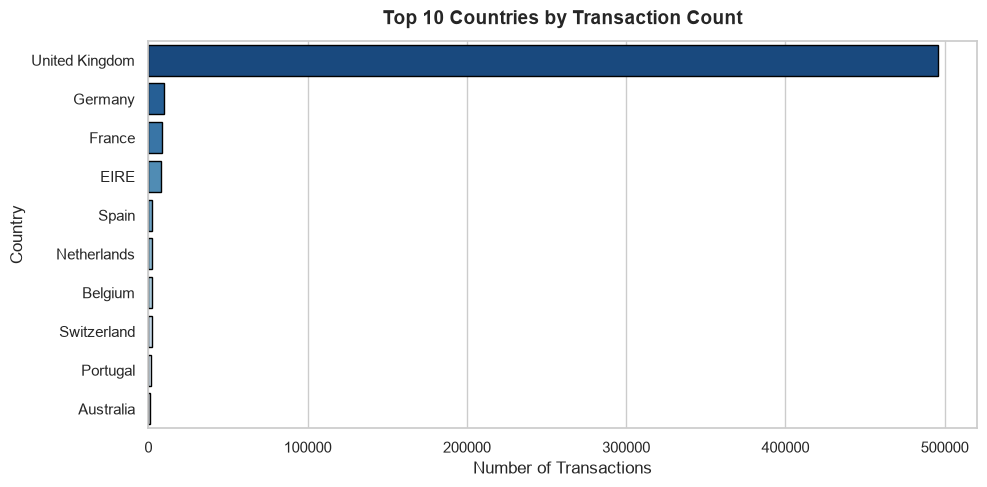

In [13]:
top_countries = df['Country'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, palette="Blues_r", legend=False, edgecolor='black')
plt.title("Top 10 Countries by Transaction Count", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Number of Transactions", fontsize=12)
plt.ylabel("Country", fontsize=12)
plt.tight_layout()

# Save output plot
plot_2_path = os.path.join(OUTPUTS_DIR, "top_10_countries.png")
plt.savefig(plot_2_path, dpi=300)
print(f"Saved chart to: {plot_2_path}")
plt.show()


### 12.3 Purchasing Activity by Hour of Day

Saved chart to: ..\outputs\hourly_purchasing_activity.png


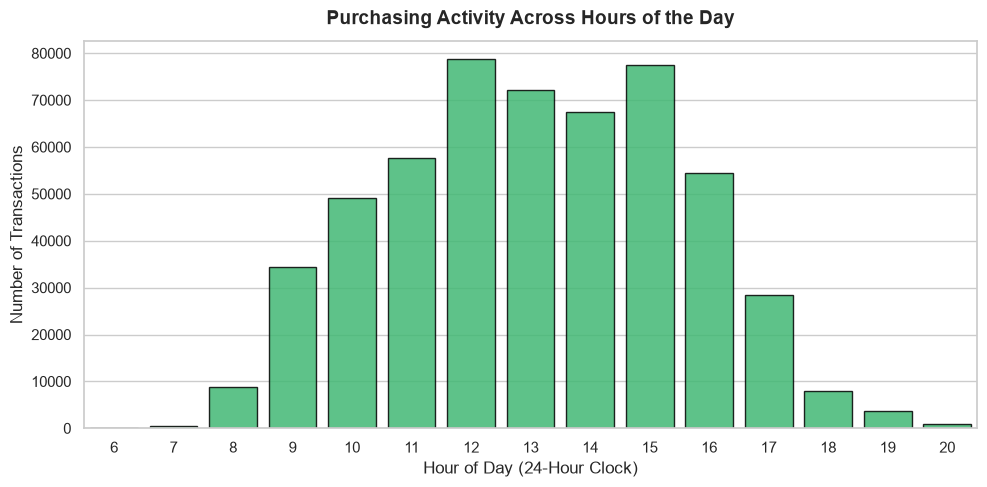

In [14]:
hourly_counts = df['Hour'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(x=hourly_counts.index, y=hourly_counts.values, color='#2ecc71', edgecolor='black', alpha=0.85)
plt.title("Purchasing Activity Across Hours of the Day", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Hour of Day (24-Hour Clock)", fontsize=12)
plt.ylabel("Number of Transactions", fontsize=12)
plt.tight_layout()

# Save output plot
plot_3_path = os.path.join(OUTPUTS_DIR, "hourly_purchasing_activity.png")
plt.savefig(plot_3_path, dpi=300)
print(f"Saved chart to: {plot_3_path}")
plt.show()

### 12.4 Top 10 Best Selling Products (by Quantity Sold)

Saved chart to: ..\outputs\top_10_products_by_quantity.png


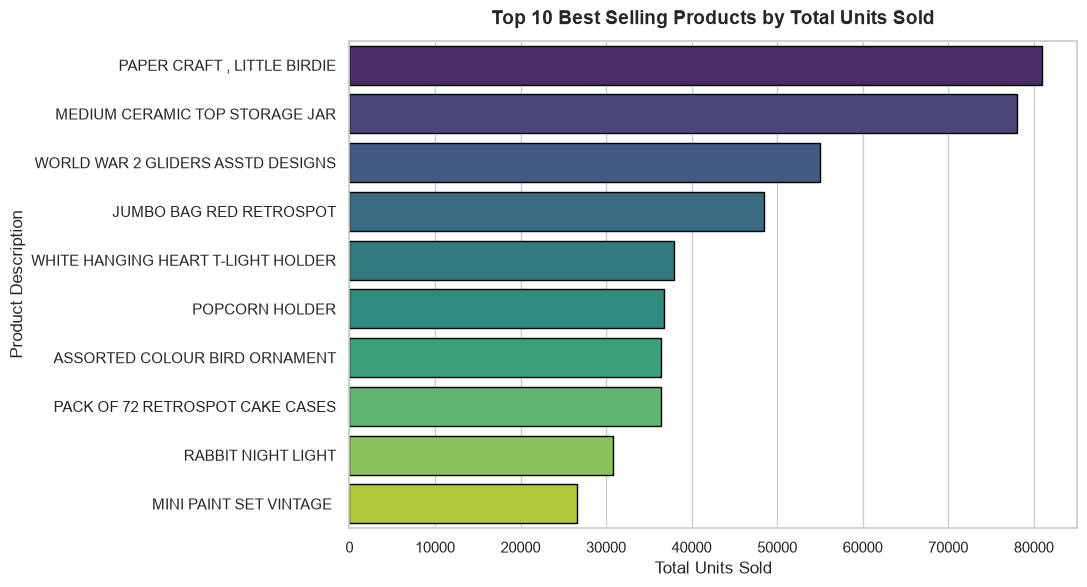

In [15]:
top_products = (
    df[df['Quantity'] > 0]
    .groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))
sns.barplot(x=top_products.values, y=top_products.index, hue=top_products.index, palette="viridis", legend=False, edgecolor='black')
plt.title("Top 10 Best Selling Products by Total Units Sold", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Total Units Sold", fontsize=12)
plt.ylabel("Product Description", fontsize=12)
plt.tight_layout()

# Save output plot
plot_4_path = os.path.join(OUTPUTS_DIR, "top_10_products_by_quantity.png")
plt.savefig(plot_4_path, dpi=300)
print(f"Saved chart to: {plot_4_path}")
plt.show()


## 13. Summary of EDA Findings

### Key Takeaways from Exploratory Analysis:
1. **Dataset Overview:** The dataset records retail transactions from Dec 2010 to Dec 2011, providing extensive visibility into transactional trends.
2. **Data Health & Completeness:** 
   - Missing values are concentrated in `CustomerID` and `Description`. Unregistered customer transactions remain valuable for sales and volume analysis.
   - A small percentage of duplicate rows exist and should be noted.
3. **Anomalies & Cancellations:**
   - Transactions with `'C'` prefixed invoices represent cancellations and customer returns.
   - Retaining cancellations is essential for accurately reporting net sales and return rates rather than inflating revenue figures.
   - Non-standard records with zero or negative unit prices correspond to administrative adjustments, damaged inventory, or manual charges.
4. **Geographic Concentration:** The overwhelming majority of orders originate from the United Kingdom, followed by major European markets (Germany, France, Ireland).
5. **Temporal Patterns:** Purchasing peaks during business hours (11:00 AM to 3:00 PM), and sales activity shows pronounced seasonal acceleration entering Q4 (autumn and pre-holiday season).

---
**Submission Note:** This notebook concludes Task 2 EDA for the CodeAlpha Data Analytics Internship.